In [1]:
import pandas as pd
import numpy as np
import lifelines 
import sksurv as sks
import matplotlib.pyplot as plt



import lifelines as ll
from lifelines import KaplanMeierFitter
import subprocess
import threading as th
import multiprocessing as mp
import sys


sys.path.append("../src/")
import sim_adj as sm
import bart_surv_adj as sb
import arviz as az
# import brt_adj as sb

import pymc as pm 
import pymc_bart as pb
import random



/Users/jacobtiegs/projects/bart_paper/bart_survival_paper_1000/.venv/lib/python3.12/site-packages/arviz/__init__.py:110: MigrationWarning: arviz.InferenceData is no longer available on the arviz package; ArviZ now uses xarray's DataTree for the same role. See the migration guide: https://python.arviz.org/en/latest/user_guide/migration_guide.html#datatree
  warnings.warn(


In [2]:
def reindex(e):
    q, z = np.unique(e, return_index=True)
    
    for i,v in enumerate(e):
        # print(i)
        # indx = np.where(q == i)
        indx = q.tolist().index(v)
        # print(indx)
        e[i]= indx
    return e

In [16]:
def get_quant_events(qnt_t, event):
	q = np.array(qnt_t)
	et_ = event["t_event"].copy()
	et_out = event["t_event"].copy()
	es_out = event["status"].copy()
	for i in range(q.shape[0]):
		if i == 0:
			msk = et_<=q[i]
			et_out[msk] = q[i]
			# print(np.unique(et_out))
		else:
			msk = (q[i-1] < et_) & (et_ <= q[i])
			et_out[msk] = q[i]
			# print(np.unique(et_out))
			if i == q.shape[0]-1:
				msk = et_ > q[i]
				et_out[msk] = q[i]
				es_out[msk] = 0

	return {"t_event":et_out, "status":es_out}

def cox_ph_3_2(x_mat, event_dict, times, test):
    cph = lifelines.CoxPHFitter()
    q = np.hstack([event_dict["t_event"].reshape(-1,1),event_dict["status"].reshape(-1,1),x_mat]) 
    col = ["T", "E"] + [f"x_{i}" for i in range(x_mat.shape[1])] 
    q = pd.DataFrame(q, columns=col)

    cph.fit(q , "T", "E")
    cph_sv = cph.predict_survival_function(x_mat, times=times).to_numpy().T
    cph_sv_test = cph.predict_survival_function(test, times=times).to_numpy().T
    return cph_sv, cph_sv_test

def get_py_bart_surv3_2(x_mat, event_dict, model_dict, sampler_dict, test):
    # event_dict["t_event"] = reindex(event_dict["t_event"])
    # print(event_dict["t_event"])
    # return
    trn = sb.get_surv_pre_train(y_time = event_dict["t_event"], y_status=event_dict["status"], x = x_mat, weight=None)
    post_test = sb.get_posterior_test(y_status=event_dict["status"], y_time=event_dict["t_event"], x=x_mat)
    # y2 = trn["y"].flatten()
    # y2[y2==0] = -1

    BSM = sb.BartSurvModel(model_config=model_dict, sampler_config=sampler_dict)
    # trn["w"][trn["x"][:,0]== trn["x"][:,0].max()] = 10
    # print(trn["x"][:,0].max())
    # return 1
    # BSM.offset = -1
    BSM.fit(y=trn["y"], X=trn["x"], weights=trn["w"], coords = trn["coord"], random_seed=99)
    # post1 = BSM.sample_posterior_predictive(X_pred=post_test["post_x"], coords=post_test["coords"])
    post1 = BSM.sample_posterior_predictive(X_pred=post_test["post_x"], coords=post_test["coords"])
    sv_prob = sb.get_sv_prob(post1, post_test["coords"])
    # uniq_t = BSM.uniq_times

    # do test
    # post_test_test = sb.get_posterior_test(y_sk = , x_test = test) # old
    post_test_test = sb.get_posterior_test(y_status=event_dict["status"], y_time=event_dict["t_event"], x=test)
    # post_test = BSM.sample_posterior_predictive(X_pred=post_test_test["post_x"], coords=post_test_test["coords"])
    post_test = BSM.sample_posterior_predictive(X_pred=post_test_test["post_x"], coords=post_test_test["coords"])
    sv_prob_test = sb.get_sv_prob(post_test, post_test_test["coords"])

    
    del BSM
    childs = mp.active_children()
    for child in childs:
        child.kill()
    # return sv_prob, sv_prob_test
    return sv_prob, sv_prob_test

# np.arange(11)
def save_to_csv(event_dict, x_mat, file="exp1_tmp.csv"):
    """helper function that passes the simulated event dataset to a csv
    - Used for R-bart

    Args:
        event_dict (_type_): _description_
        x_mat (_type_): _description_
        file (str, optional): _description_. Defaults to "exp1_tmp.csv".
    """
    col = ["t","s"] + ["x"+str(i) for i in range(x_mat.shape[1])]
    df = pd.DataFrame(np.hstack(
        [
            event_dict["t_event"],
            event_dict["status"],
            x_mat
        ]
    ),columns= col)
    exp_name = file
    path = f"../data/{exp_name}"
    with open(path, 'w') as f:
        df.to_csv(f, index=False)
    # df.to_csv(path,index = False)

def get_r_bart3_2(event_dict, x_mat, x_mat_tst, event_dict_tst):
    save_to_csv(event_dict, x_mat, file="exp3_tmp.csv")
    save_to_csv(event_dict_tst, x_mat_tst, file="exp3_tmp_tst.csv")
    
    subprocess.call("/usr/local/bin/Rscript --vanilla ../R/bart_3.R", shell=True)
    # with open("../data/exp3_tmp_out3.csv","r") as f:
        # r_sv = pd.read_csv(f).values
    r_sv = pd.read_csv("../data/exp3_tmp_out3_mu.csv").values
    r_sv_l = pd.read_csv("../data/exp3_tmp_out3_cil.csv").values
    r_sv_h = pd.read_csv("../data/exp3_tmp_out3_cih.csv").values

    r_sv_t = pd.read_csv("../data/exp3_tmp_out3_mu_t.csv").values
    r_sv_l_t = pd.read_csv("../data/exp3_tmp_out3_cil_t.csv").values
    r_sv_h_t = pd.read_csv("../data/exp3_tmp_out3_cih_t.csv").values

    return r_sv, r_sv_l, r_sv_h, r_sv_t, r_sv_l_t, r_sv_h_t

def rsqr(true, est):
    SSR = np.sum(np.power(true - est, 2))
    SST = np.sum(np.power(true - np.mean(true), 2))
    return 1-(SSR/SST)

def medabs(true, est):
    mab = np.median(np.abs(true-est))
    return mab

def rmse(true, est):
    # true = check_array(true)
    # est = check_array(est)
    out = np.sqrt(np.power((true - est),2).mean(0))
    return out

def bias(true, est):
    # true = check_array(true)
    # est = check_array(est)
    out = (true-est).mean(0)
    return out


In [ ]:

# comp 3
SPLIT_RULES3 =  [
    "pmb.ContinuousSplitRule()", # time
    "pmb.ContinuousSplitRule()", 
 	"pmb.ContinuousSplitRule()",
  	"pmb.ContinuousSplitRule()",
  	"pmb.ContinuousSplitRule()",
	"pmb.ContinuousSplitRule()",
	"pmb.ContinuousSplitRule()",
	"pmb.ContinuousSplitRule()",
	"pmb.ContinuousSplitRule()",
 	"pmb.ContinuousSplitRule()",
  	"pmb.ContinuousSplitRule()"
]
MODEL_DICT3 = {"trees": 50,
	"split_rules": SPLIT_RULES3
}

SAMPLER_DICT3 = { # new
	"draws": 500,
	"tune": 500,
	"cores": 4,
	"chains": 4,
	"compute_convergence_checks": False
}

EXP_NAME = "cmplx_new"
RUN_NAME = "cmplx_1_400_200_2_test"
RUN_NAME_cmplx3 = "cmplx_3_400"

###########################
# ITERATIONS
SEED_ADDL=99
N = [400]
N_cmplx3 = [400, 1000, 4000]
ITERS_cmplx3 = 2
PLOT_ALL=True



In [6]:

def get_sim(rng, N, type, x_vars, VAR_CLASS, VAR_PROB, scale_f, shape_f, cens_scale):
    """Generates simulation dataest

    Args:
        rng (_type_): if int, generate new rng seeded as int value.
        N (_type_): _description_
        type (_type_): _description_
        x_vars (_type_): _description_
        VAR_CLASS (_type_): _description_
        VAR_PROB (_type_): _description_
        scale_f (_type_): _description_
        shape_f (_type_): _description_
        cens_scale (_type_): _description_

    Returns:
        _type_: _description_
    """
    x_mat = sm.get_x_matrix(
        N = N,
        x_vars = x_vars, 
        VAR_CLASS=VAR_CLASS,
        VAR_PROB= VAR_PROB,
        rng = rng
    )

    event_dict, sv_true, sv_scale_true = sm.simulate_survival(
        x_mat = x_mat,
        scale_f=scale_f,
        shape_f=shape_f,
        cens_scale=cens_scale,
        rng = rng,
        eos = 100
    )
    return type, x_mat, event_dict, sv_true, sv_scale_true



mean shape 2.2941300139285716
mean scale 92.17932415714286
mean time draws 85.28530854499616
cens mean 223.7242857142857


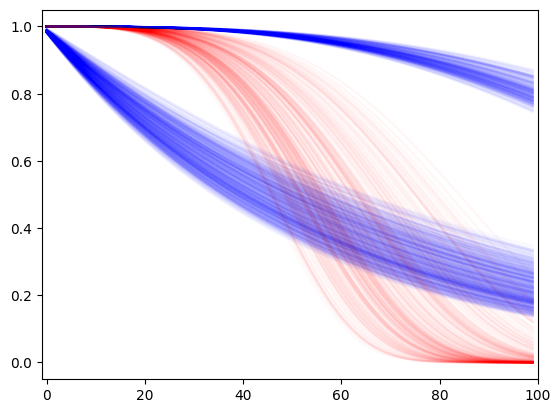

In [8]:
complex_3 = {
    "type": "Complex, continuous, 20% cens",
    "x_vars": 10, 
    # "VAR_CLASS": [1,1,1,1,1,1,1,1,1,1],
    "VAR_CLASS": [2,2,1,1,1,1,1,1,1,1],
    # "VAR_PROB":[None,None,None,None,None,None,None,None,None,None],
    "VAR_PROB":[.5,.5,None,None,None,None,None,None,None,None],
    # "scale_f" : "np.exp(3 + 0.5*np.sin(np.pi * x_mat[:,0] * x_mat[:,1]) + np.power((x_mat[:,2]-0.5), 2) + 0.5* x_mat[:,3] + 0.25 * x_mat[:,4])",
    # "scale_f": "20 + 5*(x_mat[:,0] + x_mat[:,1] + x_mat[:,2] + x_mat[:,3] + x_mat[:,4] + x_mat[:,5] + 10*x_mat[:,6])",
    "scale_f": "50 + \
        100*x_mat[:,0] -\
        100*x_mat[:,1]*x_mat[:,0]+ \
        10*x_mat[:,2] + \
        20*np.power(x_mat[:,3],2) + \
        20 * x_mat[:,3] * x_mat[:,4]",
        # 5*x_mat[:,3] +\
        # 10*np.sin(x_mat[:,2]*x_mat[:,0]*x_mat[:,1]) +\
        # 25*x_mat[:,4]* x_mat[:,0] - 25*x_mat[:,4]*x_mat[:,1]*x_mat[:,0]",
        # 10 * x_mat[:,3] + 0 * x_mat[:,3]*x_mat[:,0]*x_mat[:,1]",
    "shape_f": "1 + \
        2*x_mat[:,0] + \
        1*x_mat[:,1]*x_mat[:,0] + \
        .1*x_mat[:,1]*np.power(x_mat[:,4],2)", #
        # .5*x_mat[:,2]*x_mat[:,0] * x_mat[:,1] +\
        # .5 * x_mat[:,4]*x_mat[:,0] - .5 *x_mat[:,4]*x_mat[:,0]*x_mat[:,1] +\
        # .5 * x_mat[:,4]*x_mat[:,1] - .5*x_mat[:,4]*x_mat[:,0]*x_mat[:,1]",
    "cens_scale":2.5
    # "eos":200
}

rng = np.random.default_rng()
N= 1000
N_test = 400

scenario, x_mat, event_dict, sv_true, sv_scale_true = get_sim(rng, N + N_test, **complex_3)


sv = sv_true["sv_true"]
x_mat
plt.xlim(-1,100)
for i in range(1,sv.shape[0]):
    # if (x_mat[i,0] == 1) & (x_mat[i,1] ==0):
    if (x_mat[i,0] == 1) & (x_mat[i,1] ==1):
    # if ((x_mat[i,4]> .5) & (x_mat[i,3] > .5)):
        plt.plot(sv[i], color="red", alpha=.02)
    else:
    # tmp = x_mat[i,0] * x_mat[i,1]
    # if ((tmp > .45) & (tmp <= .55)):
        plt.plot(sv[i], color="blue", alpha=.02)
    # else:
        # plt.plot(sv[i], color="red", alpha=.02)

In [10]:
x_mat.shape
out = pd.DataFrame(x_mat, columns = ["x_"+str(i) for i in range(10)])
out["time"] = event_dict["t_event"]
out["status"] = event_dict["status"]
out.to_csv("tmp_r.csv")

In [9]:
event_dict["t_event"]
pre = sb.get_surv_pre_train(y_time=event_dict["t_event"], y_status= event_dict["status"], x=x_mat, time_scale=10)
pos = sb.get_posterior_test(y_time=event_dict["t_event"], y_status=event_dict["status"], x= x_mat, time_scale=10)

In [70]:
I = 10
msk = pre["x"][:,0] <=I
pre["y"][msk].flatten().mean()

0.09606665849773312

In [71]:
trnr = pd.read_csv("trnr.csv").iloc[:,1:]
trnr = trnr.to_numpy()
trnry = trnr[:,0]
trnrx = trnr[:,1:]
tstr = pd.read_csv("tstr.csv").iloc[:,1:]
tstr = tstr.to_numpy()
# trnrx

In [60]:
# np.all(pre["x"][msk,:] == trnrx)
# tstr.shape
# pos["post_x"][msk2,:].shape
y2 = pre["y"][msk].flatten()
y2[y2==0] = -1
# y2[y2==0] = -np.abs(np.random.normal(0,1,y2[y2==0].shape[0]))
# y2[y2==1] = -np.abs(np.random.normal(0,1,y2[y2==1].shape[0]))
y2

array([-1., -1., -1., ..., -1., -1.,  1.])

In [797]:
# tstr.shape
# np.all(tstr == pos["post_x"][msk2,:])

True

In [225]:
event_dict

with pm.Model() as m1:
    x_data = pm.Data("x_data", pre["x"][msk,:])
    # x_data = pm.Data("x_data", trnrx)
    f = pb.BART(
        "f",
        X = x_data, 
        Y = pre["y"].flatten()[msk],
        # Y = y2,
        # Y = trnry.flatten(),
        m = 200,
        separate_trees=False,
        split_rules= [pb.ContinuousSplitRule] + [pb.OneHotSplitRule, pb.OneHotSplitRule] + [pb.ContinuousSplitRule]*8,
        # split_prior=[1,.2,.2,.5,.2,.5,.5,.5,.5,.5,.5],
        split_prior=[1,1,1,1,1,1,1,1,1,1,1],
        beta=.6
        # alpha=0.
    )
    
    # mu = pm.Deterministic("mu", pm.math.invlogit(f))
    mu = pm.Deterministic("mu", pm.math.invprobit(f))
    y_pred = pm.Bernoulli("y", p=mu, observed=pre["y"][msk].flatten(), shape=x_data.shape[0])
    # y_pred = pm.Bernoulli("y", p=mu, observed=trnry.flatten(), shape=x_data.shape[0])
    
    idata = pm.sample(chains=12, cores =12,tune=1000, draws=1000, 
                      compute_convergence_checks=False, random_seed=123,
                      pgbart={
                          "num_particles":10,
                          "batch":(.4,.8)
                          }
                      )

    # idata = pm.sample_posterior_predictive()

# I= 4
msk2 = pos["post_x"][:,0] <= I
pos["post_x"][msk2,:]
with m1:
    pm.set_data({"x_data":pos["post_x"][msk2,:]})
    # pm.set_data({"x_data":tstr})
    post = pm.sample_posterior_predictive(idata, var_names=["mu"], extend_inferencedata=False)

0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 1_000 tune and 1_000 draw iterations (12_000 + 12_000 draws total) took 1597 seconds.
Sampling: [f]


Output()

In [ ]:
# trss = list(m1.basic_RVs[0].owner.op.all_trees)
# # for i in trss.
# # len(trss[0][0][3].tree_structure)
# ll = []
# for i in range(len(trss)):
#     # print(i)      
#     for j in range(trss[i][0].shape[0]):
#         ll.append(max(trss[i][0][j].tree_structure.keys()))
#     # print(len(trss[i][0][1].tree_structure))
#     # print(max(trss[i][0][1].tree_structure.keys()))
#         # print(j)
# # np.mean(ll)
# max(ll)

26

In [ ]:
# p1 = post.posterior_predictive["mu"].values.reshape(1200,-1).mean(0).reshape(5000,5)


In [ ]:
# msktmp = (x_mat[:,1] == 1) & (x_mat[:,0]==0)
# msktmp2 = (x_mat[:,1] == 1) & (x_mat[:,0]==1)
# tmp = x_mat[msktmp,:]
# tmp.shape
# event_dict["t_event"][msktmp].mean()
# event_dict["t_event"][msktmp2].mean()
# # event_dict["status"][msktmp].mean()
# tmpmsk =((pre["x"][:,1] == 1) & (pre["x"][:,2] == 1))
# pre["y"][tmpmsk].mean()


# event_dict["status"][msktmp2].mean()

0.12873796249366448

(-0.05, 1.0)

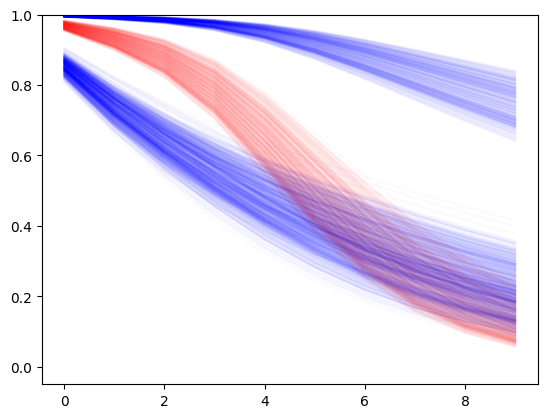

In [227]:
p1 = post.posterior_predictive["mu"].values.reshape(-1, 1400,10).mean(0)
# p1 = post.posterior_predictive["mu"].values.reshape(-1,I,1400).mean(0).T
# sb.get_sv_prob(post)
p2 = np.cumprod(1-p1,1)

for i in np.arange(1400):
# for i in np.arange(p2.shape[0]):
    # if ((x_mat[i,4]> .5) & (x_mat[i,3] > .5)):
    if (x_mat[i,0] == 1) & (x_mat[i,1] ==1):
    # if ((x_mat[i,1] == 1) & (x_mat[i,0]==0)):        
        plt.plot(p2[i,:], color="red", alpha=0.02)
        # plt.plot(sv[i], color="red", alpha=.02)
    else:
    # tmp = x_mat[i,0] * x_mat[i,1]
    # if ((tmp > .45) & (tmp <= .55)):
        plt.plot(p2[i,:], color="blue", alpha=0.02)
        # plt.plot(sv[i], color="blue", alpha=.02)
plt.ylim(-.05,1)    

# plt.xlim(0,11)

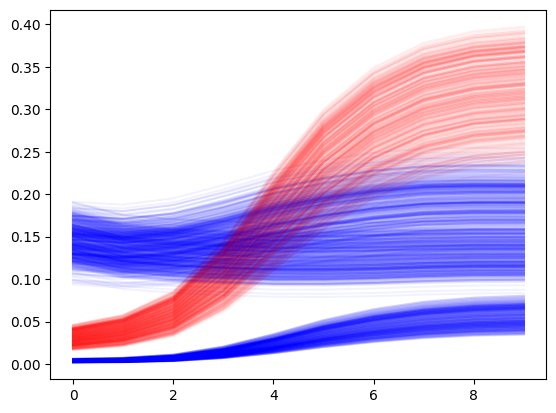

In [228]:
for i in np.arange(1400):
# for i in np.arange(p2.shape[0]):
    # if ((x_mat[i,4]> .5) & (x_mat[i,3] > .5)):
    if (x_mat[i,0] == 1) & (x_mat[i,1] ==1):
    # if (x_mat[i,1] == 1):        
        plt.plot(p1[i,:], color="red", alpha=0.05)
        # plt.plot(sv[i], color="red", alpha=.02)
    else:
    # tmp = x_mat[i,0] * x_mat[i,1]
    # if ((tmp > .45) & (tmp <= .55)):
        plt.plot(p1[i,:], color="blue", alpha=0.05)
        # plt.plot(sv[i], color="blue", alpha=.02)

In [290]:
p1[:,6].mean()

0.15523257406107727

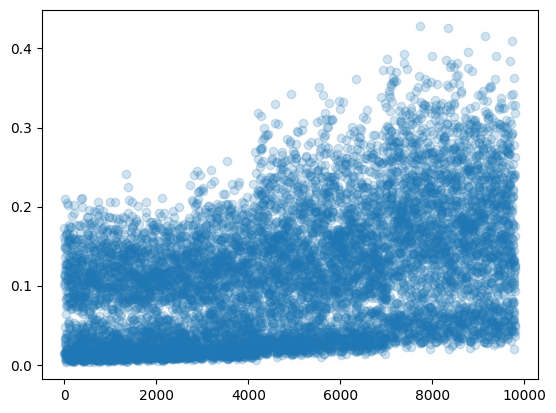

In [255]:
# plt.plot(p1.flatten(),"o",alpha=.2)
qq = post.posterior_predictive["mu"].values.mean(0).mean(0)

# plt.plot(range(qq.shape[0]), qq, "o", alpha=0.2)
qq2 = qq.reshape(1400,7).T.flatten()
plt.plot(range(qq.shape[0]), qq2, "o", alpha=0.2)
# qq

In [214]:
# del BSM
childs = mp.active_children()
for child in childs:
    print(child)
    # child.kill()

In [491]:
N_test = 1000

# shuffle to cut
# go = True
# # inflate = 100
# other_count = 0
# 
# tmp_seed = seed*inflate
tmp_seed = 11
rng = np.random.default_rng(tmp_seed)
scenario, x_mat, event_dict, sv_true, sv_scale_true = get_sim(rng, N + N_test, **complex_3)
# index =list(range(N + N_test))
# random.Random(tmp_seed).shuffle(index)

event_dict_upt = {
    "t_event":event_dict["t_event"][:N],
    "status": event_dict["status"][:N],
}
x_mat_t = x_mat[N:]
qnt_t = np.ceil(np.quantile(range(int(event_dict_upt["t_event"].max())), [.05, 0.1,.2, .3, .4, .5, .6,.7,.8, .9,1])).astype("int")
# print(qnt_t)
print(qnt_t.shape)
print(qnt_t)

event_dict2 = get_quant_events(qnt_t=qnt_t, event=event_dict_upt)
event_dict2_upt = event_dict2

print(event_dict2["t_event"].shape)
print(np.unique(event_dict2["t_event"]).shape)
print(np.unique(event_dict["t_event"]).shape)
print(np.unique(event_dict2["t_event"]))
event_dict2_upt_tst = {
    "t_event": event_dict["t_event"][N:],
    "status": event_dict["status"][N:]
}


mean shape 2.2217174235000003
mean scale 91.19727379000001
503.0
mean time draws 84.81872310138517
cens mean 220.403
(11,)
[ 5 10 20 30 40 50 60 70 80 90 99]
(1000, 1)
(11,)
(100,)
[ 5. 10. 20. 30. 40. 50. 60. 70. 80. 90. 99.]


In [495]:

if qnt_t.shape[0] == np.unique(event_dict2_upt["t_event"]).shape[0]:
    print("match size")
    go = False
    print(tmp_seed)
else:
    print("NO")
    go = True
cens_perc2 = event_dict2["status"][event_dict2["status"] == 0].shape[0]/event_dict2["status"].shape[0]        
uniq_t = np.unique(event_dict["t_event"])
true_t = sv_true["true_times"]

# cox model
cph_sv, cph_sv_test = cox_ph_3_2(x_mat[:N,:], event_dict_upt, times=qnt_t, test = x_mat_t)


match size
11


(-1.0, 100.0)

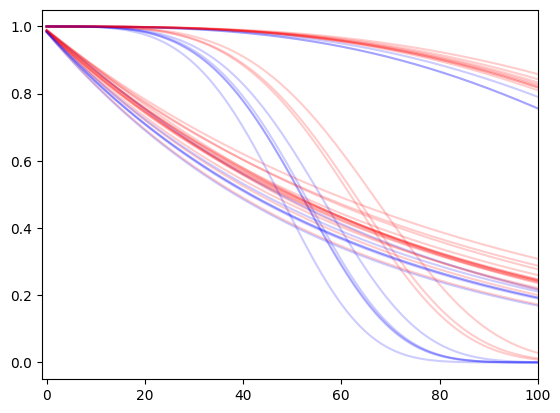

In [496]:
sv = sv_true["sv_true"]
# plt.plot(sv[1,:])
# plt.xlim(-1,200)
for i in range(40):
    # if (x_mat[i,0] == 1) & (x_mat[i,1] ==0):
    # if (x_mat[i,0] == 0) & (x_mat[i,1] ==1):
    # if (x_mat[i,0] == 1):
    if (x_mat[i,3] >.5):
        plt.plot(sv[i], color="red", alpha=.2)
    else:
    # tmp = x_mat[i,0] * x_mat[i,1]
    # if ((tmp > .45) & (tmp <= .55)):
        plt.plot(sv[i], color="blue", alpha=.2)
plt.xlim(-1,100)

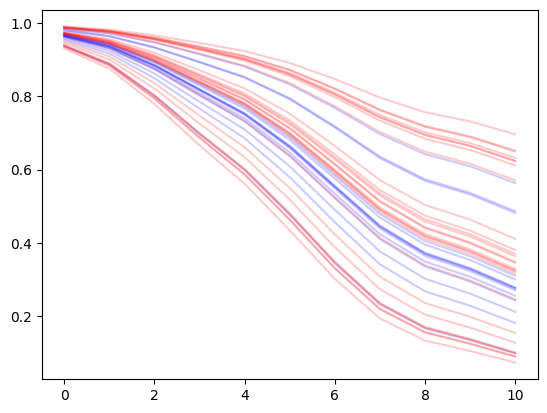

In [497]:
cph_sv
# plt.xlim(-1,200)
for i in range(40):
    # plt.plot(cph_sv[i], color="red", alpha=.2)
    # if (x_mat[i,0] == 1) & (x_mat[i,1] ==0):
    # if (x_mat[i,0] == 0) & (x_mat[i,1] ==1):
    if (x_mat[i,3] >.5):
    # if (x_mat[i,0] == 1):
        plt.plot(cph_sv[i], color="red", alpha=.2)
    else:
    # tmp = x_mat[i,0] * x_mat[i,1]
    # if ((tmp > .45) & (tmp <= .55)):
        plt.plot(cph_sv[i], color="blue", alpha=.2)

In [584]:
SPLIT_RULES3 = [
    # "pmb.OneHotSplitRule()",
    "pmb.ContinuousSplitRule()", # time
    # "pmb.ContinuousSplitRule()", 
    "pmb.OneHotSplitRule()", 
 	"pmb.ContinuousSplitRule()",
	# "pmb.OneHotSplitRule()", 
  	"pmb.ContinuousSplitRule()",
  	"pmb.ContinuousSplitRule()",
	"pmb.ContinuousSplitRule()",
	"pmb.ContinuousSplitRule()",
	"pmb.ContinuousSplitRule()",
	"pmb.ContinuousSplitRule()",
 	"pmb.ContinuousSplitRule()",
  	"pmb.ContinuousSplitRule()"
]
MODEL_DICT3 = {"trees": 20,
	"split_rules": SPLIT_RULES3,
	"beta":1
}

SAMPLER_DICT3 = { # new
	"draws": 100,
	"tune": 1000,
	"cores": 12,
	"chains": 12,
	"compute_convergence_checks": False,
	"pgbart":{
		"num_particles":10,
		"batch":(.5,.1)
		}
}

model_dict = MODEL_DICT3
sampler_dict = SAMPLER_DICT3
# pb_sv, pb_sv_test = get_py_bart_surv3_2(x_mat=x_mat[index[:N],:], event_dict=event_dict2_upt, model_dict=model_dict, sampler_dict=sampler_dict, test = x_mat_t)
pb_sv, pb_sv_test = get_py_bart_surv3_2(x_mat=x_mat[:N,:], event_dict=event_dict2_upt, model_dict=model_dict, sampler_dict=sampler_dict, test = x_mat_t)
# p_sv = pb_sv["sv"].mean(0)
pb_svm = pb_sv["sv"].mean(0)
p_sv_testm = pb_sv_test["sv"].mean(0)

/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/model/core.py:946: FutureWarning: Coords are now always mutable. Specifying `mutable` will raise an error in a future release
  warnings.warn(
/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/.venv/lib/python3.12/site-packages/pymc/data.py:321: FutureWarning: MutableData is deprecated. All Data variables are now mutable. Use Data instead.
  warnings.warn(
Multiprocess sampling (12 chains in 12 jobs)
PGBART: [f]


Output()

Sampling 12 chains for 1_000 tune and 100 draw iterations (12_000 + 1_200 draws total) took 81 seconds.


In [502]:
pb_svm.shape

(1000, 11)

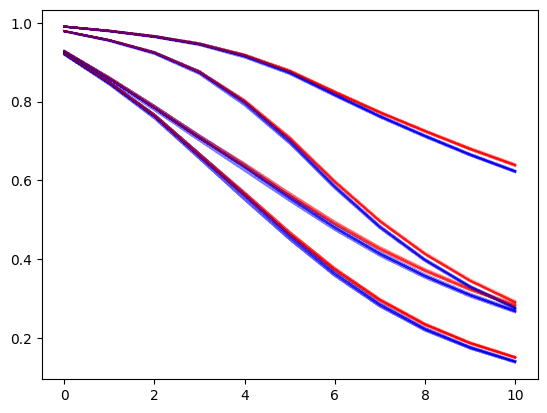

In [585]:
pb_svm
for i in range(pb_svm.shape[0]):
    if (x_mat[i,3] >.5):
        plt.plot(pb_svm[i], color="red", alpha=.02)
    else:
        plt.plot(pb_svm[i], color="blue", alpha=.02)

In [569]:
r_sv, r_sv_l, r_sv_h, r_sv_t, r_sv_l_t, r_sv_h_t = get_r_bart3_2(
    event_dict2_upt, 
    x_mat=x_mat[:N,:], 
    x_mat_tst = x_mat[N:,:],
    event_dict_tst = event_dict2_upt_tst
)

Loading required package: nlme
Loading required package: survival


[1] "/Users/jacobtiegs/projects/bart_paper/bart_survival_paper/new_runs"
 num [1:1000, 1:10] 0 0 1 0 0 1 0 0 1 1 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
 num [1:1000, 1:10] 1 0 0 1 1 1 0 0 1 0 ...
 - attr(*, "dimnames")=List of 2
  ..$ : NULL
  ..$ : chr [1:10] "x0" "x1" "x2" "x3" ...
NULL
*****Calling gbart: type=2
*****Data:
data:n,p,np: 6752, 11, 11000
y1,yn: 0.000000, 1.000000
x1,x[n*p]: 5.000000, 0.462000
xp1,xp[np*p]: 5.000000, 0.462000
*****Number of Trees: 50
*****Number of Cut Points: 10 ... 100
*****burn,nd,thin: 250,1670,10
*****Prior:beta,alpha,tau,nu,lambda,offset: 2,0.95,0.212132,3,1,-1.39142
*****Dirichlet:sparse,theta,omega,a,b,rho,augment: 0,0,1,0.5,1,11,0
*****printevery: 100

MCMC
done 0 (out of 1920)
done 100 (out of 1920)
done 200 (out of 1920)
done 300 (out of 1920)
done 400 (out of 1920)
done 500 (out of 1920)
done 600 (out of 1920)
done 700 (out of 1920)
done 800 (out of 1920)
done 900 (out of 1920)
done 

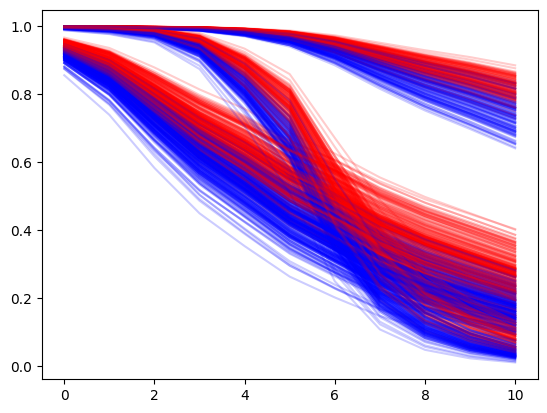

In [507]:
# r_sv.shape
# pb_svm
for i in range(r_sv.shape[0]):
    # plt.plot(pb_svm[i], color="red", alpha=.2)
    # if (x_mat[i,0] == 1) & (x_mat[i,1] ==0):
    # if (x_mat[i,0] == 0) & (x_mat[i,1] ==1):
    # if (x_mat[i,0] == 1):
    if (x_mat[i,3] >.5):
        plt.plot(r_sv[i], color="red", alpha=.2)
    else:
    # tmp = x_mat[i,0] * x_mat[i,1]
    # if ((tmp > .45) & (tmp <= .55)):
        plt.plot(r_sv[i], color="blue", alpha=.2)

In [232]:

# test plot

pb_svm.shape
# true_trn[:,1].shape
sv_true["sv_true"].shape

(5000, 517)

In [572]:
time_indx = [np.where(true_t == i)[0][0] for i in qnt_t]
true_trn = sv_true["sv_true"][:, time_indx][:N,:]
true_test = sv_true["sv_true"][:, time_indx][N:,:]

p_rmse = []
r_rmse = []
c_rmse = []
p_bias = []
r_bias = []
c_bias = []

p_mabs = []
r_mabs = []
c_mabs = []

for i in range(true_trn.shape[1]):
    p_rmse.append(rmse(true_trn[:,i], pb_svm[:,i]))
    r_rmse.append(rmse(true_trn[:,i], r_sv[:,i]))
    c_rmse.append( rmse(true_trn[:,i], cph_sv[:,i]))
    p_bias.append(bias(true_trn[:,i], pb_svm[:,i]))
    r_bias.append(bias(true_trn[:,i], r_sv[:,i]))
    c_bias.append(bias(true_trn[:,i], cph_sv[:,i]))

    p_mabs.append(medabs(true_trn[:,i], pb_svm[:,i]))
    r_mabs.append(medabs(true_trn[:,i], r_sv[:,i]))
    c_mabs.append(medabs(true_trn[:,i], cph_sv[:,i]))


df_tst2 = pd.DataFrame([p_rmse, r_rmse, c_rmse, p_bias, r_bias, c_bias, p_mabs, 
                            r_mabs, c_mabs]).T
df_tst2.columns = "p_rmse,r_rmse,c_rmse,p_bias,r_bias,c_bias,p_mabs,r_mabs,c_mabs".split(",")


df_tst2

,p_rmse,r_rmse,c_rmse,p_bias,r_bias,c_bias,p_mabs,r_mabs,c_mabs
0,0.012041,0.009710,0.027472,0.001434,0.000371,0.001480,0.008476,0.003793,0.019363
1,0.023920,0.017821,0.052992,0.004239,-0.001355,-0.002693,0.015305,0.007261,0.035736
2,0.050784,0.031597,0.097188,-0.008606,-0.011305,-0.012949,0.046206,0.010203,0.067264
3,0.065454,0.038602,0.123226,-0.009255,-0.014036,-0.009675,0.060090,0.014763,0.096969
4,0.067844,0.048444,0.132907,-0.012241,-0.017698,-0.014521,0.054081,0.024494,0.097412
5,0.064882,0.058747,0.136048,-0.010679,-0.017886,-0.009981,0.041421,0.027079,0.114097
6,0.074502,0.071017,0.155511,-0.005339,-0.005179,0.003633,0.043127,0.033215,0.152448
7,0.087196,0.073616,0.183788,-0.001161,0.005128,0.019158,0.054506,0.036517,0.154400
8,0.091102,0.065889,0.201341,0.000426,0.003454,0.017807,0.063660,0.039930,0.163259
9,0.086983,0.056237,0.205359,0.000082,-0.001134,0.003070,0.064478,0.038077,0.162606


In [573]:
p_rmse = []
r_rmse = []
c_rmse = []


p_bias = []
r_bias = []
c_bias = []

p_mabs = []
r_mabs = []
c_mabs = []

p_rsq = []
r_rsq = []
c_rsq = []



# res
for i in range(true_trn.shape[1]):
    p_rmse.append(rmse(true_test[:,i], p_sv_testm[:,i]))
    r_rmse.append(rmse(true_test[:,i], r_sv_t[:,i]))
    c_rmse.append( rmse(true_test[:,i], cph_sv_test[:,i]))

    p_bias.append(bias(true_test[:,i], p_sv_testm[:,i]))
    r_bias.append(bias(true_test[:,i], r_sv_t[:,i]))
    c_bias.append(bias(true_test[:,i], cph_sv_test[:,i]))

    p_mabs.append(medabs(true_test[:,i], p_sv_testm[:,i]))
    r_mabs.append(medabs(true_test[:,i], r_sv_t[:,i]))
    c_mabs.append(medabs(true_test[:,i], cph_sv_test[:,i]))

    p_rsq.append(rsqr(true_test[:,i], p_sv_testm[:,i]))
    r_rsq.append(rsqr(true_test[:,i], r_sv_t[:,i]))
    c_rsq.append(rsqr(true_test[:,i], cph_sv_test[:,i]))

deciles= [.05, 0.1,.2, .3, .4, .5, .6,.7,.8, .9,1][::-1]
itersss = np.repeat(tmp_seed, 11)
nnn = np.repeat(N, 11)
df_tst2 = pd.DataFrame([p_rmse, r_rmse, c_rmse, p_bias, r_bias, c_bias, p_mabs, 
                r_mabs, c_mabs, p_rsq, r_rsq, c_rsq, deciles, itersss, nnn]).T

df_tst2.columns = "p_rmse,r_rmse,c_rmse,p_bias,r_bias,c_bias,p_mabs,r_mabs,c_mabs,p_rsq,r_rsq,c_rsq,deciles,seed,n".split(",")
df_tst2


,p_rmse,r_rmse,c_rmse,p_bias,r_bias,c_bias,p_mabs,r_mabs,c_mabs,p_rsq,r_rsq,c_rsq,deciles,seed,n
0,0.012094,0.010007,0.028601,0.001737,0.000608,0.001012,0.009090,0.003918,0.023417,0.891605,0.925782,0.393785,1.00,11.0,1000.0
1,0.024083,0.018215,0.055155,0.004947,-0.000830,-0.003334,0.016376,0.007377,0.042589,0.884678,0.934031,0.395131,0.90,11.0,1000.0
2,0.051221,0.031670,0.100787,-0.007291,-0.010551,-0.013779,0.047106,0.009583,0.076588,0.844273,0.940465,0.397056,0.80,11.0,1000.0
3,0.066163,0.038550,0.127471,-0.007753,-0.013171,-0.011238,0.063105,0.015344,0.106535,0.853490,0.950261,0.456170,0.70,11.0,1000.0
4,0.068915,0.048793,0.137227,-0.011524,-0.016794,-0.017764,0.054554,0.027220,0.102227,0.880879,0.940286,0.527676,0.60,11.0,1000.0
5,0.068235,0.061483,0.140776,-0.011505,-0.017576,-0.015891,0.044198,0.029614,0.119211,0.904992,0.922866,0.595614,0.50,11.0,1000.0
6,0.079670,0.075071,0.159920,-0.007500,-0.003808,-0.004758,0.046145,0.035826,0.157675,0.898769,0.910119,0.592127,0.40,11.0,1000.0
7,0.090633,0.077773,0.186235,-0.004145,0.006918,0.009521,0.057121,0.039742,0.154042,0.894410,0.922249,0.554170,0.30,11.0,1000.0
8,0.092009,0.068190,0.202911,-0.003041,0.005149,0.007698,0.065665,0.043433,0.166563,0.902743,0.946580,0.526982,0.20,11.0,1000.0
9,0.086837,0.056780,0.207803,-0.003923,0.000037,-0.007443,0.065921,0.040885,0.164087,0.915056,0.963683,0.513561,0.10,11.0,1000.0


In [17]:


def big_loop(seed, N):
    N_test = 400
    # shuffle to cut
    go = True
    inflate = 100
    other_count = 0
    while go:
        tmp_seed = seed*inflate
        rng = np.random.default_rng(tmp_seed)
        scenario, x_mat, event_dict, sv_true, sv_scale_true = get_sim(rng, N + N_test, **complex_3)
        # index =list(range(N + N_test))
        # random.Random(tmp_seed).shuffle(index)

        event_dict_upt = {
            "t_event":event_dict["t_event"][:N],
            "status": event_dict["status"][:N],
        }
        x_mat_t = x_mat[N:,:]
        qnt_t = np.ceil(np.quantile(range(int(event_dict_upt["t_event"].max())), [.05, 0.1,.2, .3, .4, .5, .6,.7,.8, .9,1])).astype("int")
        print(qnt_t.shape)
        print(qnt_t)

        event_dict2 = get_quant_events(qnt_t=qnt_t, event=event_dict_upt)
        event_dict2_upt = event_dict2
        # print(event_dict2["t_event"].shape)
        # print(np.unique(event_dict2["t_event"]).shape)
        # print(np.unique(event_dict["t_event"]).shape)
        # print(np.unique(event_dict2["t_event"]))
        event_dict2_upt_tst = {
            "t_event": event_dict["t_event"][N:],
            "status": event_dict["status"][N:]
        }
        if qnt_t.shape[0] == np.unique(event_dict2_upt["t_event"]).shape[0]:
            print("match size")
            go = False
            print(tmp_seed)
        else:
            print("NO")
            go = True
        if other_count > 10:
            assert(False)
        inflate += 100
        other_count += 1


    cens_perc2 = event_dict2["status"][event_dict2["status"] == 0].shape[0]/event_dict2["status"].shape[0]        
    print(cens_perc2)
    # uniq_t = np.unique(event_dict["t_event"])a
    true_t = sv_true["true_times"]
    # cox model
    cph_sv, cph_sv_test = cox_ph_3_2(x_mat[:N,:], event_dict_upt, times=qnt_t, test = x_mat_t)
    
    # P-bart
    model_dict = MODEL_DICT3
    sampler_dict = SAMPLER_DICT3
    pb_sv_trn, pb_sv_test = get_py_bart_surv3_2(
        x_mat=x_mat[:N,:], 
        event_dict=event_dict2_upt, 
        model_dict=model_dict, 
        sampler_dict=sampler_dict, 
        test = x_mat_t)
    p_sv = pb_sv_trn["sv"].mean(0)
    p_sv_test = pb_sv_test["sv"].mean(0)

    # r-BART
    r_sv, r_sv_l, r_sv_h, r_sv_t, r_sv_l_t, r_sv_h_t = get_r_bart3_2(
        event_dict2_upt, 
        x_mat=x_mat[:N,:], 
        x_mat_tst = x_mat[N:,:],
        event_dict_tst = event_dict2_upt_tst
    )
    # print(r_sv.shape)
    # print(r_sv)
        
    # plt
    plt.figure()
    sv = sv_true["sv_true"]
    for i in range(20):
        plt.plot(p_sv[i], color="green", alpha=.4, label="p")
        plt.plot(r_sv[i], color="blue", alpha=.4,label= 'r')
        plt.plot(cph_sv[i], color="red", alpha=.1, label="c")
    plt.show()

    # set up the times
    time_indx = [np.where(true_t == i)[0][0] for i in qnt_t]
    true_trn = sv_true["sv_true"][:, time_indx][:N,:]
    true_test = sv_true["sv_true"][:, time_indx][N:,:]

    # trn
    p_rmse = []
    r_rmse = []
    c_rmse = []
    p_bias = []
    r_bias = []
    c_bias = []
    p_mabs = []
    r_mabs = []
    c_mabs = []
    p_rsq = []
    r_rsq = []
    c_rsq = []
    # res
    for i in range(true_trn.shape[1]):
        p_rmse.append(rmse(true_trn[:,i], p_sv[:,i]))
        r_rmse.append(rmse(true_trn[:,i], r_sv[:,i]))
        c_rmse.append( rmse(true_trn[:,i], cph_sv[:,i]))

        p_bias.append(bias(true_trn[:,i], p_sv[:,i]))
        r_bias.append(bias(true_trn[:,i], r_sv[:,i]))
        c_bias.append(bias(true_trn[:,i], cph_sv[:,i]))

        p_mabs.append(medabs(true_trn[:,i], p_sv[:,i]))
        r_mabs.append(medabs(true_trn[:,i], r_sv[:,i]))
        c_mabs.append(medabs(true_trn[:,i], cph_sv[:,i]))

        p_rsq.append(rsqr(true_trn[:,i], p_sv[:,i]))
        r_rsq.append(rsqr(true_trn[:,i], r_sv[:,i]))
        c_rsq.append(rsqr(true_trn[:,i], cph_sv[:,i]))

    deciles= [.05, 0.1,.2, .3, .4, .5, .6,.7,.8, .9,1][::-1]
    itersss = np.repeat(tmp_seed, 11)
    nnn = np.repeat(N, 11)
    df_trn2 = pd.DataFrame([p_rmse, r_rmse, c_rmse, p_bias, r_bias, c_bias, p_mabs, 
                            r_mabs, c_mabs, p_rsq, r_rsq, c_rsq, deciles, itersss, nnn]).T

    df_trn2.columns = "p_rmse,r_rmse,c_rmse,p_bias,r_bias,c_bias,p_mabs,r_mabs,c_mabs,p_rsq,r_rsq,c_rsq,deciles,seed,n".split(",")


    # tst
    p_rmse = []
    r_rmse = []
    c_rmse = []
    p_bias = []
    r_bias = []
    c_bias = []
    p_mabs = []
    r_mabs = []
    c_mabs = []
    p_rsq = []
    r_rsq = []
    c_rsq = []
    # res
    for i in range(true_test.shape[1]):
        p_rmse.append(rmse(true_test[:,i], p_sv_test[:,i]))
        r_rmse.append(rmse(true_test[:,i], r_sv_t[:,i]))
        c_rmse.append( rmse(true_test[:,i], cph_sv_test[:,i]))

        p_bias.append(bias(true_test[:,i], p_sv_test[:,i]))
        r_bias.append(bias(true_test[:,i], r_sv_t[:,i]))
        c_bias.append(bias(true_test[:,i], cph_sv_test[:,i]))

        p_mabs.append(medabs(true_test[:,i], p_sv_test[:,i]))
        r_mabs.append(medabs(true_test[:,i], r_sv_t[:,i]))
        c_mabs.append(medabs(true_test[:,i], cph_sv_test[:,i]))

        p_rsq.append(rsqr(true_test[:,i], p_sv_test[:,i]))
        r_rsq.append(rsqr(true_test[:,i], r_sv_t[:,i]))
        c_rsq.append(rsqr(true_test[:,i], cph_sv_test[:,i]))

    deciles= [.05, 0.1,.2, .3, .4, .5, .6,.7,.8, .9,1][::-1]
    itersss = np.repeat(tmp_seed, 11)
    nnn = np.repeat(N, 11)
    df_tst2 = pd.DataFrame([p_rmse, r_rmse, c_rmse, p_bias, r_bias, c_bias, p_mabs, 
                            r_mabs, c_mabs, p_rsq, r_rsq, c_rsq, deciles, itersss, nnn]).T

    df_tst2.columns = "p_rmse,r_rmse,c_rmse,p_bias,r_bias,c_bias,p_mabs,r_mabs,c_mabs,p_rsq,r_rsq,c_rsq,deciles,seed,n".split(",")


    return(df_trn2, df_tst2)

In [ ]:
df_trn = pd.DataFrame()
df_tst = pd.DataFrame()
for i in range(500):
# for i in [1]:
    trn_df, tst_df = big_loop(seed = i, N=400)
    df_trn = pd.concat([trn_df, df_trn])
    df_tst = pd.concat([tst_df, df_tst])

df_trn.to_csv("complex1_N_400_trn.csv")
df_tst.to_csv("complex1_N_400_tst.csv")

In [20]:
df_trn

,p_rmse,r_rmse,c_rmse,p_bias,r_bias,c_bias,p_mabs,r_mabs,c_mabs,p_rsq,r_rsq,c_rsq,deciles,seed,n
0,0.021616,0.023324,0.027008,-0.003364,-0.003318,-0.002815,0.009412,0.007931,0.019696,0.654062,0.597246,0.459986,1.00,1000.0,400.0
1,0.041031,0.043598,0.054203,-0.007520,-0.007785,-0.013614,0.018440,0.015197,0.036560,0.666157,0.623088,0.417418,0.90,1000.0,400.0
2,0.066059,0.066321,0.092751,-0.010105,-0.008368,-0.009768,0.035421,0.027657,0.068841,0.742735,0.740693,0.492832,0.80,1000.0,400.0
3,0.077126,0.073449,0.116738,0.009108,0.007177,0.009200,0.040728,0.033623,0.089993,0.804041,0.822280,0.551063,0.70,1000.0,400.0
4,0.081876,0.080532,0.128151,0.010311,0.012684,0.012053,0.038258,0.035978,0.102579,0.837158,0.842460,0.601063,0.60,1000.0,400.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6,0.112104,0.110839,0.172784,-0.026543,-0.017656,-0.021025,0.060615,0.060868,0.134929,0.801149,0.805610,0.527620,0.40,100.0,400.0
7,0.111460,0.113357,0.195467,-0.020370,-0.023598,-0.020116,0.067520,0.069237,0.169392,0.848177,0.842965,0.533074,0.30,100.0,400.0
8,0.107669,0.110740,0.214388,-0.030570,-0.035542,-0.029253,0.068314,0.068683,0.185762,0.876680,0.869546,0.511066,0.20,100.0,400.0
9,0.105178,0.108295,0.224591,-0.040090,-0.041551,-0.048817,0.065018,0.066061,0.196242,0.885736,0.878862,0.478988,0.10,100.0,400.0


In [39]:
import logging
logging.basicConfig(
    filename='app.log', 
    filemode='a', 
    format='%(asctime)s - %(levelname)s - %(message)s',
    level=logging.INFO
)

In [ ]:
df_trn = pd.DataFrame()
df_tst = pd.DataFrame()
for i in range(500):
    logging.info(f"iteration {i}")

    trn_df, tst_df = big_loop(seed = i, N=1000)
    df_trn = pd.concat([trn_df, df_trn])
    df_tst = pd.concat([tst_df, df_tst])


df_trn.to_csv("complex1_N_1000_trn.csv")
df_tst.to_csv("complex1_N_1000_tst.csv")

In [42]:
df_tst.groupby("deciles").mean()
# df_tst.groupby("deciles").mean()

# for i in []

,p_rmse,r_rmse,c_rmse,p_bias,r_bias,c_bias,p_mabs,r_mabs,c_mabs,p_rsq,r_rsq,c_rsq,seed,n
deciles,,,,,,,,,,,,,,
0.05,0.064950,0.065985,0.202145,-0.005238,-0.007747,-0.005021,0.042821,0.041542,0.174383,0.950607,0.949064,0.531322,24950.0,1000.0
0.10,0.070113,0.070409,0.208835,-0.007697,-0.009547,-0.004271,0.047345,0.045363,0.181502,0.944820,0.944339,0.518456,24950.0,1000.0
0.20,0.078143,0.077278,0.206114,-0.008194,-0.008685,-0.002733,0.048783,0.047639,0.179655,0.929853,0.931301,0.517924,24950.0,1000.0
0.30,0.084729,0.083279,0.190076,-0.007622,-0.007566,-0.001010,0.045703,0.045875,0.170013,0.906657,0.909602,0.535193,24950.0,1000.0
0.40,0.082199,0.081599,0.164066,-0.005852,-0.006403,0.000645,0.041275,0.042305,0.151201,0.889919,0.891188,0.565777,24950.0,1000.0
0.50,0.069816,0.071082,0.145208,-0.004049,-0.004755,0.001564,0.036193,0.036705,0.121474,0.898267,0.894315,0.564683,24950.0,1000.0
0.60,0.057050,0.059129,0.140448,-0.002328,-0.003003,0.001064,0.028885,0.028074,0.109844,0.916206,0.909820,0.499813,24950.0,1000.0
0.70,0.048967,0.050148,0.129810,-0.000829,-0.001259,0.000749,0.023237,0.019567,0.105789,0.916707,0.912624,0.427289,24950.0,1000.0
0.80,0.040008,0.040344,0.100824,-0.001092,-0.000375,-0.000088,0.019637,0.014784,0.079583,0.900782,0.898796,0.383793,24950.0,1000.0


In [ ]:
import logging
logging.basicConfig(
    filename='app2.log', 
    filemode='a', 
    format='%(asctime)s - %(levelname)s - %(message)s',
    level=logging.INFO
)

df_trn = pd.DataFrame()
df_tst = pd.DataFrame()
for i in range(500):
    logging.info(f"iteration {i}")

# for i in [1]:
    trn_df, tst_df = big_loop(seed = i, N=4000)
    df_trn = pd.concat([trn_df, df_trn])
    df_tst = pd.concat([tst_df, df_tst])

df_trn.to_csv("complex1_N_4000_trn.csv")
df_tst.to_csv("complex1_N_4000_tst.csv")

In [47]:
df_tst.groupby("deciles").mean()

,p_rmse,r_rmse,c_rmse,p_bias,r_bias,c_bias,p_mabs,r_mabs,c_mabs,p_rsq,r_rsq,c_rsq,seed,n
deciles,,,,,,,,,,,,,,
0.05,0.039640,0.038267,0.198180,-0.004186,-0.005231,-0.004736,0.025094,0.022616,0.172087,0.981711,0.982872,0.548133,24950.0,4000.0
0.10,0.043978,0.041315,0.204894,-0.005325,-0.005769,-0.003626,0.028596,0.024175,0.174683,0.978377,0.980814,0.534892,24950.0,4000.0
0.20,0.051346,0.046050,0.202187,-0.005197,-0.004858,-0.002226,0.030177,0.026470,0.169771,0.969698,0.975527,0.534476,24950.0,4000.0
0.30,0.056603,0.049197,0.185846,-0.005411,-0.005390,-0.000554,0.027867,0.026003,0.165990,0.958230,0.968371,0.553961,24950.0,4000.0
0.40,0.053759,0.047575,0.159538,-0.005397,-0.005865,0.000432,0.024892,0.023608,0.154829,0.952785,0.962936,0.588029,24950.0,4000.0
0.50,0.043540,0.040794,0.141093,-0.004162,-0.004854,0.001024,0.021480,0.019935,0.121418,0.960456,0.965140,0.588832,24950.0,4000.0
0.60,0.033677,0.032989,0.137495,-0.002632,-0.003322,0.000921,0.016781,0.015076,0.109931,0.970889,0.971939,0.521615,24950.0,4000.0
0.70,0.028013,0.027224,0.127747,-0.001946,-0.002361,0.000121,0.012211,0.009662,0.109620,0.972808,0.974273,0.446727,24950.0,4000.0
0.80,0.022894,0.021700,0.099310,-0.001249,-0.001308,-0.000207,0.010466,0.006068,0.079303,0.967535,0.970745,0.403628,24950.0,4000.0


In [48]:
n400 = pd.read_csv("complex1_N_400_tst.csv")
n1000 = pd.read_csv("complex1_N_1000_tst.csv")
n4000 = pd.read_csv("complex1_N_4000_tst.csv")

In [ ]:
# you are here - should be able to generate the graphs with the 500 iters

In [ ]:

cols = ["p_rmse", "r_rmse", "c_rmse","p_bias", "r_bias", "c_bias", "deciles"]
m400 = pd.DataFrame(n400[cols].groupby("deciles").mean().sort_values(by="deciles", ascending=False).loc[[.9,.7,.5,.3,.1]]).T
m1000 = pd.DataFrame(n1000[cols].groupby("deciles").mean().sort_values(by="deciles", ascending=False).loc[[.9,.7,.5,.3,.1]]).T
m4000 = pd.DataFrame(n4000[cols].groupby("deciles").mean().sort_values(by="deciles", ascending=False).loc[[.9,.7,.5,.3,.1]]).T

pd.concat([m400,m1000, m4000]).to_excel("complex_res_mean.xlsx")

NameError: name 'pd' is not defined

In [50]:
# n400["deciles"] = 1 - n400["deciles"]
# n1000["deciles"] = 1 - n1000["deciles"]
# n4000["deciles"] = 1 - n4000["deciles"]
# n4000["deciles"]
n400["idx"] = n400["Unnamed: 0"]
n400

,Unnamed: 0,p_rmse,r_rmse,c_rmse,p_bias,r_bias,c_bias,p_mabs,r_mabs,c_mabs,p_rsq,r_rsq,c_rsq,deciles,seed,n,idx
0,0,0.017050,0.018213,0.031093,-0.000234,0.002006,-0.005344,0.008717,0.007417,0.022032,0.780009,0.748982,0.268428,1.00,49900.0,400.0,0
1,1,0.032183,0.033807,0.059301,0.000216,0.004024,-0.007634,0.017293,0.014438,0.044630,0.790484,0.768804,0.288628,0.90,49900.0,400.0,1
2,2,0.053756,0.053985,0.107236,-0.003107,-0.003884,-0.013080,0.030865,0.024898,0.083448,0.825980,0.824495,0.307497,0.80,49900.0,400.0,2
3,3,0.079275,0.077901,0.137364,0.007780,0.002393,0.000630,0.047737,0.051645,0.112485,0.785693,0.793058,0.356554,0.70,49900.0,400.0,3
4,4,0.097307,0.090417,0.152672,-0.008088,-0.013561,-0.028469,0.057517,0.051905,0.107804,0.752795,0.786564,0.391462,0.60,49900.0,400.0,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5495,6,0.119053,0.119594,0.172866,-0.007473,-0.010559,-0.009789,0.070556,0.079723,0.150925,0.773439,0.771379,0.522342,0.40,0.0,400.0,6
5496,7,0.126986,0.126088,0.193033,-0.017343,-0.019633,-0.023035,0.080726,0.086118,0.177394,0.794540,0.797437,0.525236,0.30,0.0,400.0,7
5497,8,0.128950,0.127358,0.203142,-0.026476,-0.029959,-0.021061,0.083861,0.086870,0.186904,0.812702,0.817297,0.535175,0.20,0.0,400.0,8
5498,9,0.129872,0.127445,0.205654,-0.035308,-0.039503,-0.029902,0.081997,0.081966,0.189905,0.814761,0.821621,0.535513,0.10,0.0,400.0,9


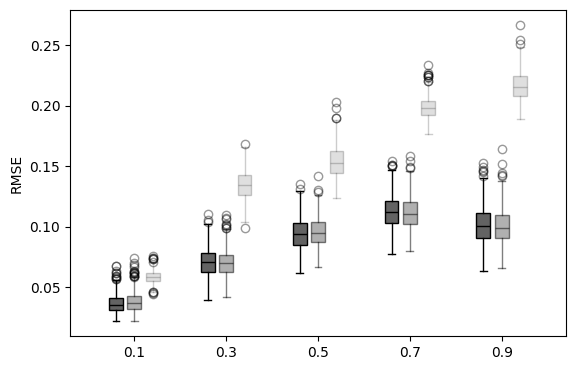

In [51]:
for i in [.9, .7, .5, .3, .1]:
# for i in [1,3,5,7,9]:
    tmp = n400[n400["deciles"]== i]
    # tmp = n400[n400["idx"]== i]
# plt.boxplot(tmp)
    tmp_rmse = tmp[["p_rmse", "r_rmse", "c_rmse"]]
    # plt.boxplot(tmp_rmse)
    pst = (1-i) * 5
    alpha3 = 0.4
    alpha2=1
    plt.boxplot(
            tmp["p_rmse"], 
            positions = [pst - .2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.5
    plt.boxplot(
            tmp["r_rmse"], 
            positions = [pst],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.2
    plt.boxplot(
            tmp["c_rmse"], 
            positions = [pst+.2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    
    # lbls = [str(i) for i in [0.1,.2, .3, .4, .5, .6,.7,.8, .9]]
lbls = [str(i) for i in [0.1, .3,  .5, .7, .9]]
# pts = np.array([0.9, .7,  .5, .3, .1]) * 5
pts = np.array([0.1, .3,  .5, .7, .9]) * 5
# pts = np.array([1, 3,  5, 7, 9]) * 5
# lbls = lbls[::-1]
plt.xticks(
    pts, lbls
    # np.hstack([pts-.2, pts, pts + .2]) ,
    # labels =  ["" + x for x in lbls] + ["R" + x for x in lbls]  + ["C" + x for x in lbls] ,
    # labels = ["p-BART " + x for x in lbls] + ["r-BART " + x for x in lbls] + ["CPHM " + x for x in lbls],
    # rotation = 90
)
plt.ylabel("RMSE")
plt.subplots_adjust(bottom=0.20)
plt.savefig("ooo_rmse_N_400.png")

In [1]:
fig,ax = plt.subplots(nrows=1,ncols=3, figsize=(20,8), sharey=True)
scale = 4
for i in [.9, .7, .5, .3, .1]:
    tmp1 = n400[n400["deciles"]== i]
    tmp2 = n1000[n1000["deciles"]== i]
    tmp3 = n4000[n4000["deciles"]== i]

    
    pst = (1-i) * scale
    alpha3 = 0.3
    alpha2=1
    ax[0].boxplot(
            tmp1["p_bias"], 
            positions = [pst - .2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.7
    ax[0].boxplot(
            tmp1["r_bias"], 
            positions = [pst],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.3
    ax[0].boxplot(
            tmp1["c_bias"], 
            positions = [pst+.2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    
    # 1000
    alpha2=1
    ax[1].boxplot(
            tmp2["p_bias"], 
            positions = [pst - .2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.7
    ax[1].boxplot(
            tmp2["r_bias"], 
            positions = [pst],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.3
    ax[1].boxplot(
            tmp2["c_bias"], 
            positions = [pst+.2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    # 4000
    alpha2=1
    ax[2].boxplot(
            tmp3["p_bias"], 
            positions = [pst - .2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            label='p-BART'if i == 0.1 else None
            )
    alpha2=0.7
    ax[2].boxplot(
            tmp3["r_bias"], 
            positions = [pst],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            label="r-BART" if i == 0.1 else None
            )
    alpha2=0.3
    ax[2].boxplot(
            tmp3["c_bias"], 
            positions = [pst+.2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            label="CPHM" if i == 0.1 else None
            )

lbls = [str(i) for i in [0.1, .3,  .5, .7, .9]]
pts = np.array([0.1, .3,  .5, .7, .9]) * scale
ax[0].set_xticks(
    pts, lbls
)

ax[1].set_xticks(
    pts,lbls
    
)

ax[2].set_xticks(
    pts,lbls
)
# ax[0].set_ylabel("Bias")
ax[0].set_ylim((-0.075, 0.075))
ax[1].set_ylim((-0.075, 0.075))
ax[2].set_ylim((-0.075, 0.075))
ax[0].axhline(0, linestyle = "--", c="black", alpha=0.2 )
ax[1].axhline(0, linestyle = "--", c="black", alpha=0.2 )
ax[2].axhline(0, linestyle = "--", c="black", alpha=0.2 )
plt.legend()

# ax[0].subplots_adjust(bottom=0.20)
# ax[1].subplots_adjust(bottom=0.20)
# ax[2].subplots_adjust(bottom=0.20)
plt.subplots_adjust(bottom=0.2)
# plt.subplots_adjust(bottom=0.2)
plt.tight_layout()
ax[0].set_ylabel("Bias")
# plt.yticks([0, .05, 0.1, 0.15, 0.2])
# ax[1].set_ylabel()
plt.savefig("../results/2_ooo_bias_comb.png")

NameError: name 'plt' is not defined

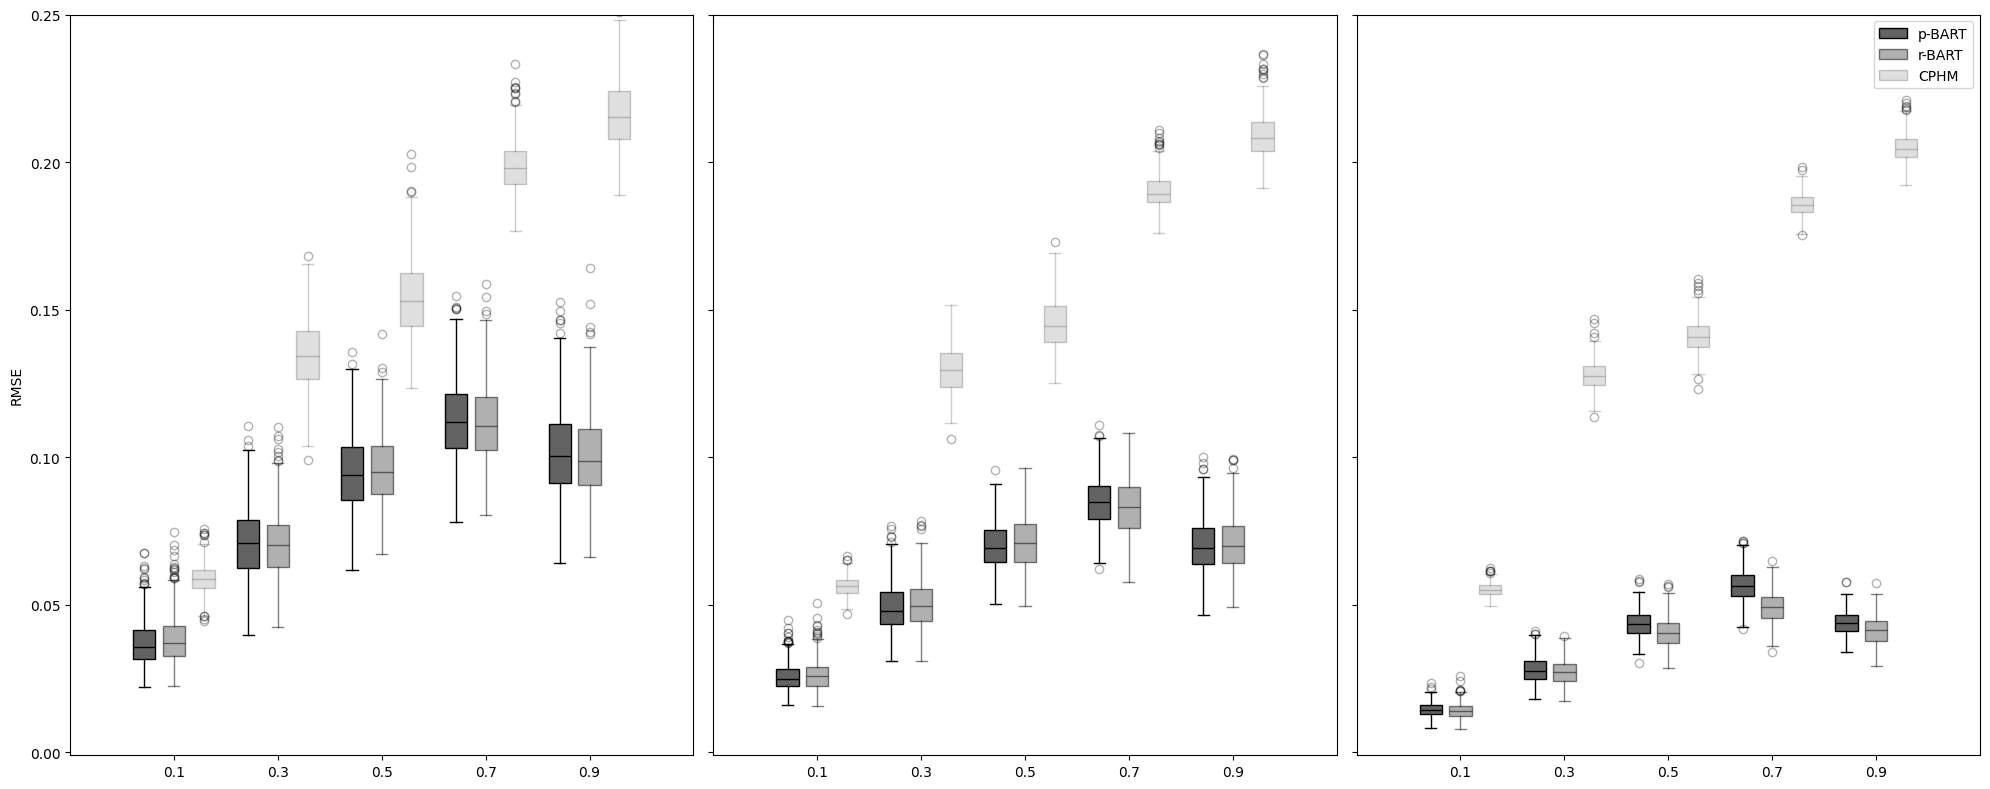

In [54]:
fig,ax = plt.subplots(nrows=1,ncols=3, figsize=(20,8), sharey=True)
scale = 3.5
# for i in [.9, .7]:#,# .5, .3, .1]:
for i in [.1, .3, .5, .7, .9]:
    tmp1 = n400[n400["deciles"]== i]
    tmp2 = n1000[n1000["deciles"]== i]
    tmp3 = n4000[n4000["deciles"]== i]

    
    pst = (1-i) * scale
    alpha3 = 0.3
    alpha2=1
    ax[0].boxplot(
            tmp1["p_rmse"], 
            positions = [pst - .2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.5
    ax[0].boxplot(
            tmp1["r_rmse"], 
            positions = [pst],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.2
    ax[0].boxplot(
            tmp1["c_rmse"], 
            positions = [pst+.2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    
    # 1000
    alpha2=1
    ax[1].boxplot(
            tmp2["p_rmse"], 
            positions = [pst - .2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.5
    ax[1].boxplot(
            tmp2["r_rmse"], 
            positions = [pst],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    alpha2=0.2
    ax[1].boxplot(
            tmp2["c_rmse"], 
            positions = [pst+.2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            )
    # 4000
    alpha2=1
    ax[2].boxplot(
            tmp3["p_rmse"], 
            positions = [pst - .2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            label="p-BART" if i == 0.1 else None
            )
    alpha2=0.5
    ax[2].boxplot(
            tmp3["r_rmse"], 
            positions = [pst],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            label="r-BART" if i == 0.1 else None
            )
    alpha2=0.2
    ax[2].boxplot(
            tmp3["c_rmse"], 
            positions = [pst+.2],
            medianprops = {"color":"black", "alpha":alpha2},
            patch_artist=True,
			boxprops = {"alpha":alpha2, "facecolor":"#636363"},
            # boxprops = {"alpha":alpha2},
			whiskerprops={"alpha":alpha2},
			capprops={"alpha":alpha2},
			flierprops={"alpha":alpha3},
            # showfliers=False
            label="CPHM" if i == 0.1 else None
            )
    
    
lbls = [str(i) for i in [0.1, .3,  .5, .7, .9]]

pts = np.array([0.1, .3,  .5, .7, .9]) * scale

ax[0].set_xticks(
    pts,lbls
)

ax[1].set_xticks(
    pts,lbls
)

ax[2].set_xticks(
    pts, lbls
)
# ax[0].set_ylabel("RMSE")
ax[0].set_ylim((-0.001, 0.25))
ax[1].set_ylim((-0.001, 0.25))
ax[2].set_ylim((-0.001, 0.25))
# ax[0].axhline(0, linestyle = "--", c="black", alpha=0.2 )
# ax[1].axhline(0, linestyle = "--", c="black", alpha=0.2 )
# ax[2].axhline(0, linestyle = "--", c="black", alpha=0.2 )
plt.legend()

ax[0].set_ylabel("RMSE")
# ax[0].subplots_adjust(bottom=0.20)
# ax[1].subplots_adjust(bottom=0.20)
# ax[2].subplots_adjust(bottom=0.20)
plt.subplots_adjust(bottom=0.2)
plt.tight_layout()
plt.yticks([0, .05, 0.1, 0.15, .2, .25])
# ax[1].set_ylabel()
plt.savefig("2_ooo_rmse_comb.png")